# 🧪 Classificação de Imagens com CNN (CIFAR-10)

In [ ]:
# 📦 1. Importação de bibliotecas
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
# 📥 2. Carregar o dataset CIFAR-10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
print("Formato dos dados de treino:", X_train.shape)
print("Formato dos dados de teste:", X_test.shape)

In [ ]:
# 🔍 3. Visualizar algumas imagens
classes = ['avião', 'automóvel', 'pássaro', 'gato', 'cervo',
           'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']

plt.figure(figsize=(10,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_train[i])
    plt.title(classes[y_train[i][0]])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# 🧼 4. Pré-processamento
X_train = X_train.astype('float32') / 255.0 #cada pixel é de 0 à 255. Então, normalizamos os valores dividindo por 255
X_test  = X_test.astype('float32') / 255.0

y_train = y_train.flatten()
y_test  = y_test.flatten()

- Se tiver dúvidas sobre convolução, ler: https://dev.to/giselyalves13/entendendo-redes-convolucionais-cnns-42h9

In [ ]:

# 🧠 5. Criar o modelo CNN
model = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),#Camanda 1: Aplica 32 filtros 3x3 com ativação ReLU. O 'padding=same' mantém a saída do mesmo tamanho da entrada (32x32).
    MaxPooling2D((2,2)),# Reduz novamente as dimensões pela metade (16x16 → 8x8), mantendo os 32 canais.
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2)),# Reduz novamente as dimensões pela metade (16x16 → 8x8), mantendo os 64 canais.
    Flatten(),# Transforma o tensor 3D de saída anterior (8x8x64 = 4096) em um vetor 1D para ser processado pela camada densa.
    Dense(128, activation='relu'),# 128 neurônios com ativação ReLU para aprender combinações não-lineares das características extraídas.
    Dropout(0.5),# Zera aleatoriamente 50% das ativações dessa camada durante o treino, para reduzir overfitting.
    Dense(10, activation='softmax')#Camada de saída: 10 neurônios (uma para cada classe do CIFAR-10), com ativação softmax para gerar uma distribuição de probabilidade.
])

model.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

In [34]:
# train_datagen = ImageDataGenerator(
#     rotation_range=15,
#     width_shift_range=0.1,
#     height_shift_range=0.1,
#     horizontal_flip=True,
# )

# # No teste, só normalização (sem aumentos!)
# test_datagen = ImageDataGenerator()

# batch_size = 64 #O batch_size define quantas imagens são processadas por época
# train_generator = train_datagen.flow(X_train, y_train, batch_size=batch_size)
# test_generator = test_datagen.flow(X_test, y_test, batch_size=batch_size)

# model.fit(
#     train_generator,
#     epochs=20,
#     validation_data=test_generator
# )


# model.fit(
#     train_generator,
#     epochs=20,
#     validation_data=test_generator
# )




/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 38ms/step - accuracy: 0.3892 - loss: 1.7082 - val_accuracy: 0.4576 - val_loss: 1.5147
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 29s 37ms/step - accuracy: 0.4061 - loss: 1.6424 - val_accuracy: 0.4623 - val_loss: 1.4864
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 29s 37ms/step - accuracy: 0.4271 - loss: 1.5933 - val_accuracy: 0.4923 - val_loss: 1.4223
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 29s 37ms/step - accuracy: 0.4417 - loss: 1.5584 - val_accuracy: 0.5078 - val_loss: 1.3813
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 29s 37ms/step - accuracy: 0.4547 - loss: 1.5153 - val_accuracy: 0.5092 - val_loss: 1.4055
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 35ms/step - accuracy: 0.4628 - loss: 1.5039 - val_accuracy: 0.5305 - val_loss: 1.3105
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 36ms/step - accuracy: 0.4734 - loss: 1.4659 - val_accuracy: 0.5289 - val_loss: 1.3032
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 29s 37ms/step - accuracy: 0.4755 - loss: 1.4620 - 

KeyboardInterrupt: 

In [ ]:

# 🚂 6. Treinamento do modelo
history = model.fit(X_train, y_train,
                    epochs=20,
                    batch_size=64,
                    validation_split=0.2)

In [ ]:
# 📈 7. Plotar curva de loss e acurácia
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='treino')
plt.plot(history.history['val_loss'], label='validação')
plt.title("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='treino')
plt.plot(history.history['val_accuracy'], label='validação')
plt.title("Acurácia")
plt.legend()

plt.show()

In [ ]:
# 🧪 8. Avaliação no conjunto de teste
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Acurácia no teste: {test_acc:.4f}")

In [ ]:
# 📊 9. Matriz de confusão
y_pred = np.argmax(model.predict(X_test), axis=1)

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Previsto")
plt.ylabel("Verdadeiro")
plt.title("Matriz de Confusão")
plt.show()

In [ ]:
# 📋 10. Relatório de classificação
print(classification_report(y_test, y_pred, target_names=classes))

In [35]:

# 🧠 5. Criar o modelo CNN
model = Sequential([
    Flatten(),# Transforma o tensor 3D de saída anterior (8x8x64 = 4096) em um vetor 1D para ser processado pela camada densa.
    Dense(10, activation='softmax')#Camada de saída: 10 neurônios (uma para cada classe do CIFAR-10), com ativação softmax para gerar uma distribuição de probabilidade.
])

model.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)            │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [37]:

# 🚂 6. Treinamento do modelo
history = model.fit(X_train, y_train,
                    epochs=10,
                    batch_size=64,#O batch_size define quantas imagens são processadas por época
                    validation_split=0.2)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3838 - loss: 1.7746 - val_accuracy: 0.3758 - val_loss: 1.8006
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3844 - loss: 1.7661 - val_accuracy: 0.3849 - val_loss: 1.7848
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3982 - loss: 1.7473 - val_accuracy: 0.3854 - val_loss: 1.7732
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3933 - loss: 1.7465 - val_accuracy: 0.3838 - val_loss: 1.7843
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3938 - loss: 1.7506 - val_accuracy: 0.3766 - val_loss: 1.7827
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3984 - loss: 1.7353 - val_accuracy: 0.3937 - val_loss: 1.7664
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3975 - loss: 1.7392 - val_accuracy: 0.3859 - val_loss: 1.7760
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4026 - loss: 1.7319 - val_accuracy: 0.

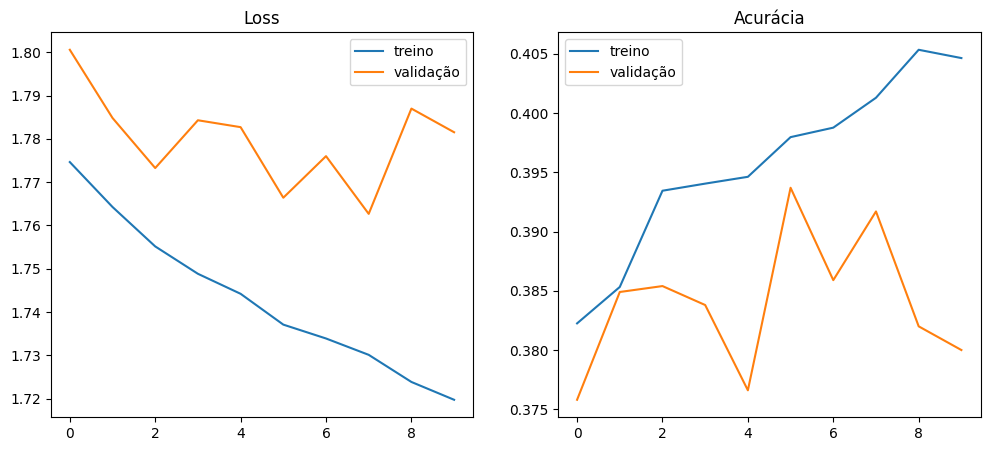

In [38]:
# 📈 7. Plotar curva de loss e acurácia
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='treino')
plt.plot(history.history['val_loss'], label='validação')
plt.title("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='treino')
plt.plot(history.history['val_accuracy'], label='validação')
plt.title("Acurácia")
plt.legend()

plt.show()

In [40]:
# 🧪 8. Avaliação no conjunto de teste
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Acurácia no teste: {test_acc:.4f}")

Acurácia no teste: 0.3813


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


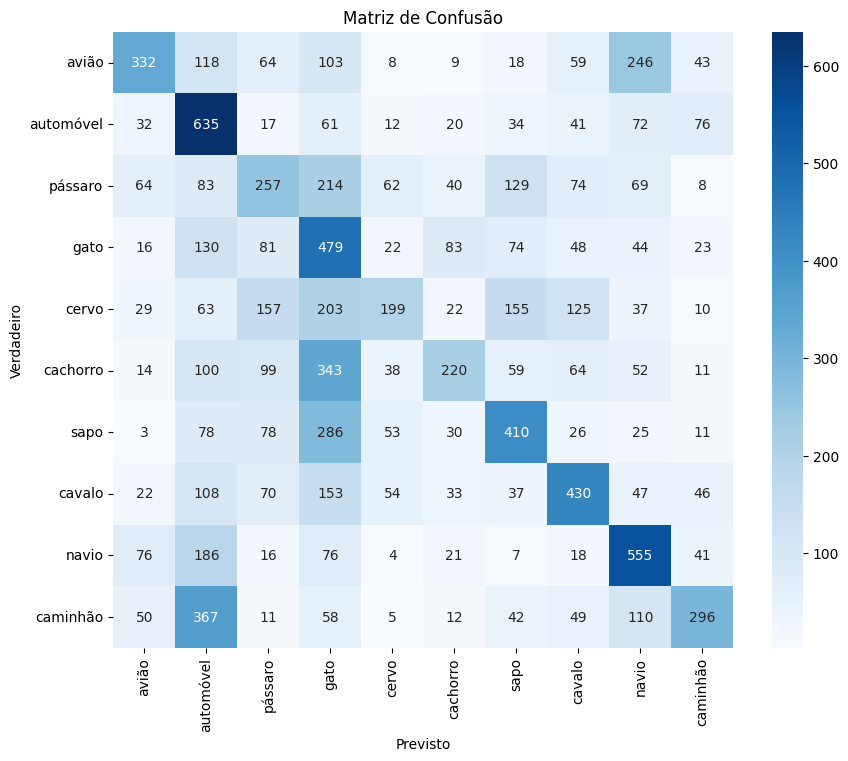

In [39]:
# 📊 9. Matriz de confusão
y_pred = np.argmax(model.predict(X_test), axis=1)

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Previsto")
plt.ylabel("Verdadeiro")
plt.title("Matriz de Confusão")
plt.show()

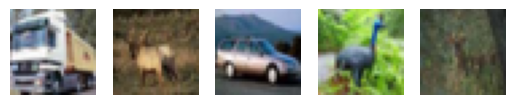

In [49]:
count = 0
for i in range(len(y_pred)):
  if y_pred[i] != y_test[i]:
    plt.subplot(2,5,count+1)
    plt.imshow(X_train[i])
    plt.title(classes[y_train[i][0]])
    plt.axis('off')
    count+=1
    if count > 4:
      break